## 1. Importação das bibliotecas

Importamos a biblioteca `pandas` para manipulação e tratamento dos dados.

In [1]:
import pandas as pd

In [23]:
import matplotlib.pyplot as plt

## 2. Leitura da camada Bronze

Carregamos o arquivo gerado na camada Bronze (`history_bronze.csv`).  
Essa é a base de dados bruta já estruturada, que será limpa e padronizada nesta camada Silver.

In [2]:
df_silver = pd.read_csv("dados/bronze/history_bronze.csv")

## 3. Avaliação da qualidade dos dados

Antes de iniciar qualquer tratamento, verificamos:
- Quantidade de valores nulos por coluna
- Quantidade de registros duplicados

**Tomada de decisão:**  
Identificamos que a única coluna com valores nulos é `TotalCharges` (278 registros). Não existem duplicatas.  
Isso orienta o foco do tratamento.

In [3]:
# verificando nulos e duplicidades

print("TOTAL DE NULOS: ",df_silver.isnull().sum())
print(" ")
print("TOTAL DE DUPLICATAS: ",df_silver.duplicated().sum())


TOTAL DE NULOS:  customerID            0
gender                0
SeniorCitizen         0
Partner               0
Dependents            0
tenure                0
PhoneService          0
MultipleLines         0
InternetService       0
OnlineSecurity        0
OnlineBackup          0
DeviceProtection      0
TechSupport           0
StreamingTV           0
StreamingMovies       0
Contract              0
PaperlessBilling      0
PaymentMethod         0
MonthlyCharges        0
TotalCharges        278
Churn                 0
CustomerFeedback      0
MonthlyIncome         0
dtype: int64
 
TOTAL DE DUPLICATAS:  0


## 4. Tradução das colunas para português

Padronizamos os nomes das colunas para o português, facilitando a leitura e a comunicação dos resultados.

**Tomada de decisão:**  
Mantivemos os nomes claros e descritivos. A coluna de tempo de permanência ficou como `Tempo_Permanencia(MESES)`.  
(Observação: futuramente pode ser renomeada para `Tempo_Permanencia_Meses` para evitar problemas em consultas SQL).

In [4]:
## Tradução para pt-br

df_silver = df_silver.rename(columns={
    "customerID": "ID_Cliente",
    "gender": "Genero",
    "SeniorCitizen": "Cliente_Idoso",
    "Partner": "Parceiro",
    "Dependents": "Dependentes",
    "tenure": "Tempo_Permanencia(MESES)",
    "PhoneService": "Servico_Telefonico",
    "MultipleLines": "Multiplas_Linhas",
    "InternetService": "Servico_Internet",
    "OnlineSecurity": "Seguranca_Online",
    "OnlineBackup": "Backup_Online",
    "DeviceProtection": "Protecao_Dispositivo",
    "TechSupport": "Suporte_Tecnico",
    "StreamingTV": "Streaming_TV",
    "StreamingMovies": "Streaming_Filmes",
    "Contract": "Contrato",
    "PaperlessBilling": "Faturamento_Sem_Papel",
    "PaymentMethod": "Metodo_Pagamento",
    "MonthlyCharges": "Cobranca_Mensal",
    "TotalCharges": "Cobranca_Total",
    "Churn": "Cancelamento",
    "CustomerFeedback": "Feedback_Cliente",
    "MonthlyIncome": "Renda_Mensal"
})

## 5. Investigação dos valores nulos em Cobranca_Total

Antes de preencher os nulos, analisamos o comportamento desses registros.

**Tomada de decisão:**  
Verificamos se os nulos estavam relacionados ao cancelamento e ao tempo de permanência.  
Isso ajuda a escolher a melhor forma de tratamento, evitando decisões arbitrárias.

In [5]:
# verificando a coluna totalcharges para tratamento
pd.set_option('display.max_columns', None)
df_silver.head()

,ID_Cliente,Genero,Cliente_Idoso,Parceiro,Dependentes,Tempo_Permanencia(MESES),Servico_Telefonico,Multiplas_Linhas,Servico_Internet,Seguranca_Online,Backup_Online,Protecao_Dispositivo,Suporte_Tecnico,Streaming_TV,Streaming_Filmes,Contrato,Faturamento_Sem_Papel,Metodo_Pagamento,Cobranca_Mensal,Cobranca_Total,Cancelamento,Feedback_Cliente,Renda_Mensal
0,4578-PHJYZ,Male,0,Yes,Yes,52,Yes,No,DSL,No,Yes,Yes,Yes,Yes,No,One year,Yes,Electronic check,68.75,3482.85,No,I have been a customer with this internet prov...,6532
1,6289-CPNLD,Male,0,Yes,Yes,33,Yes,No,DSL,No,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,73.90,2405.05,Yes,I've been a customer with this company for ove...,7634
2,2682-KEVRP,Female,1,No,No,22,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,20.05,417.00,No,I have been a customer with this company for 2...,3628
3,5697-GOMBF,Female,1,Yes,Yes,28,No,No phone service,DSL,No,No,No,No,Yes,No,Month-to-month,Yes,Electronic check,35.90,973.65,No,I have been a customer with this internet prov...,7851
4,9717-QEBGU,Male,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.30,144.00,No,I have been using the fiber optic internet ser...,1691


In [6]:
df_nulos = df_silver[df_silver["Cobranca_Total"].isnull()]

In [7]:
df_nulos.shape[0]

278

In [8]:

pd.crosstab(
    df_nulos["Cobranca_Total"].isnull(),
    df_nulos["Cancelamento"]
)

Cancelamento,No,Yes
Cobranca_Total,,
True,186,92


In [9]:
df_nulos.head()

,ID_Cliente,Genero,Cliente_Idoso,Parceiro,Dependentes,Tempo_Permanencia(MESES),Servico_Telefonico,Multiplas_Linhas,Servico_Internet,Seguranca_Online,Backup_Online,Protecao_Dispositivo,Suporte_Tecnico,Streaming_TV,Streaming_Filmes,Contrato,Faturamento_Sem_Papel,Metodo_Pagamento,Cobranca_Mensal,Cobranca_Total,Cancelamento,Feedback_Cliente,Renda_Mensal
7,8020-BWHYL,Female,1,No,No,15,Yes,No,Fiber optic,No,Yes,No,No,No,No,Month-to-month,Yes,Credit card (automatic),75.30,NaN,Yes,I recently canceled my service with this provi...,353
49,6996-KNSML,Female,0,No,No,1,Yes,No,Fiber optic,No,No,Yes,No,No,No,Month-to-month,Yes,Electronic check,74.90,NaN,Yes,I recently switched to this internet provider ...,5422
64,4951-UKAAQ,Female,0,No,No,4,Yes,Yes,Fiber optic,No,Yes,No,No,No,Yes,Month-to-month,Yes,Electronic check,88.95,NaN,Yes,I recently decided to cancel my fiber optic in...,1323
79,9360-AHGNL,Female,1,Yes,No,43,Yes,Yes,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,109.55,NaN,Yes,I have been a customer with this company for o...,6588
122,7253-UVNDW,Female,0,No,No,46,Yes,No,DSL,No,No,Yes,Yes,No,No,Two year,No,Credit card (automatic),54.35,NaN,Yes,I have been a customer with this company for 4...,5277


## 6. Tratamento da coluna Tempo_Permanencia(MESES)

Identificamos a presença do valor textual `"unknown"` nesta coluna.

**Tomada de decisão:**  
Substituímos `"unknown"` por `0` e convertemos a coluna para tipo inteiro (`Int8`).  
O valor 0 representa clientes com tempo de permanência desconhecido ou muito recente.  
Essa decisão será documentada para a análise posterior de cancelamento.

In [10]:
df_nulos["Tempo_Permanencia(MESES)"].describe()

count     278
unique     70
top         1
freq       26
Name: Tempo_Permanencia(MESES), dtype: object

In [11]:

coluna = "Tempo_Permanencia(MESES)"

# Substituindo "unknown" por 0
df_silver[coluna] = df_silver[coluna].replace("unknown", "0")

# Convertendo para inteiro
df_silver[coluna] = pd.to_numeric(
    df_silver[coluna]
).astype("Int8")

print("Total de nulos:", df_silver[coluna].isnull().sum())
print(df_silver[coluna].dtype)


Total de nulos: 0
Int8


In [12]:
# verificando nulos e duplicidades

print("TOTAL DE NULOS: ",df_silver.isnull().sum())
print(" ")
print("TOTAL DE DUPLICATAS: ",df_silver.duplicated().sum())

TOTAL DE NULOS:  ID_Cliente                    0
Genero                        0
Cliente_Idoso                 0
Parceiro                      0
Dependentes                   0
Tempo_Permanencia(MESES)      0
Servico_Telefonico            0
Multiplas_Linhas              0
Servico_Internet              0
Seguranca_Online              0
Backup_Online                 0
Protecao_Dispositivo          0
Suporte_Tecnico               0
Streaming_TV                  0
Streaming_Filmes              0
Contrato                      0
Faturamento_Sem_Papel         0
Metodo_Pagamento              0
Cobranca_Mensal               0
Cobranca_Total              278
Cancelamento                  0
Feedback_Cliente              0
Renda_Mensal                  0
dtype: int64
 
TOTAL DE DUPLICATAS:  0


## 7. Padronização dos tipos de dados

Ajustamos os tipos de cada coluna para melhorar performance, reduzir uso de memória e garantir consistência.

**Tomada de decisão:**
- Variáveis categóricas → `category`
- Cliente_Idoso → `bool`
- Valores monetários → `float32`
- Renda → `int32`
- Textos longos → `string`

Essa padronização deixa a base preparada para análise exploratória e armazenamento.

In [13]:
df_silver.dtypes

ID_Cliente                      str
Genero                          str
Cliente_Idoso                 int64
Parceiro                        str
Dependentes                     str
Tempo_Permanencia(MESES)       Int8
Servico_Telefonico              str
Multiplas_Linhas                str
Servico_Internet                str
Seguranca_Online                str
Backup_Online                   str
Protecao_Dispositivo            str
Suporte_Tecnico                 str
Streaming_TV                    str
Streaming_Filmes                str
Contrato                        str
Faturamento_Sem_Papel           str
Metodo_Pagamento                str
Cobranca_Mensal             float64
Cobranca_Total              float64
Cancelamento                    str
Feedback_Cliente                str
Renda_Mensal                  int64
dtype: object

In [14]:
df_silver = df_silver.astype({
    "ID_Cliente": "string",
    "Genero": "category",
    "Cliente_Idoso": "bool",
    "Parceiro": "category",
    "Dependentes": "category",
    "Tempo_Permanencia(MESES)": "Int8",
    "Servico_Telefonico": "category",
    "Multiplas_Linhas": "category",
    "Servico_Internet": "category",
    "Seguranca_Online": "category",
    "Backup_Online": "category",
    "Protecao_Dispositivo": "category",
    "Suporte_Tecnico": "category",
    "Streaming_TV": "category",
    "Streaming_Filmes": "category",
    "Contrato": "category",
    "Faturamento_Sem_Papel": "category",
    "Metodo_Pagamento": "category",
    "Cobranca_Mensal": "float32",
    "Cobranca_Total": "float32",
    "Cancelamento": "category",
    "Feedback_Cliente": "string",
    "Renda_Mensal": "int32"
})

In [15]:
df_silver.dtypes

ID_Cliente                    string
Genero                      category
Cliente_Idoso                   bool
Parceiro                    category
Dependentes                 category
Tempo_Permanencia(MESES)        Int8
Servico_Telefonico          category
Multiplas_Linhas            category
Servico_Internet            category
Seguranca_Online            category
Backup_Online               category
Protecao_Dispositivo        category
Suporte_Tecnico             category
Streaming_TV                category
Streaming_Filmes            category
Contrato                    category
Faturamento_Sem_Papel       category
Metodo_Pagamento            category
Cobranca_Mensal              float32
Cobranca_Total               float32
Cancelamento                category
Feedback_Cliente              string
Renda_Mensal                   int32
dtype: object

In [16]:
# verificando nulos e duplicidades

print("TOTAL DE NULOS: ",df_silver.isnull().sum())
print(" ")
print("TOTAL DE DUPLICATAS: ",df_silver.duplicated().sum())

TOTAL DE NULOS:  ID_Cliente                    0
Genero                        0
Cliente_Idoso                 0
Parceiro                      0
Dependentes                   0
Tempo_Permanencia(MESES)      0
Servico_Telefonico            0
Multiplas_Linhas              0
Servico_Internet              0
Seguranca_Online              0
Backup_Online                 0
Protecao_Dispositivo          0
Suporte_Tecnico               0
Streaming_TV                  0
Streaming_Filmes              0
Contrato                      0
Faturamento_Sem_Papel         0
Metodo_Pagamento              0
Cobranca_Mensal               0
Cobranca_Total              278
Cancelamento                  0
Feedback_Cliente              0
Renda_Mensal                  0
dtype: int64
 
TOTAL DE DUPLICATAS:  0


In [17]:
df_silver.head()

,ID_Cliente,Genero,Cliente_Idoso,Parceiro,Dependentes,Tempo_Permanencia(MESES),Servico_Telefonico,Multiplas_Linhas,Servico_Internet,Seguranca_Online,Backup_Online,Protecao_Dispositivo,Suporte_Tecnico,Streaming_TV,Streaming_Filmes,Contrato,Faturamento_Sem_Papel,Metodo_Pagamento,Cobranca_Mensal,Cobranca_Total,Cancelamento,Feedback_Cliente,Renda_Mensal
0,4578-PHJYZ,Male,False,Yes,Yes,52,Yes,No,DSL,No,Yes,Yes,Yes,Yes,No,One year,Yes,Electronic check,68.750000,3482.850098,No,I have been a customer with this internet prov...,6532
1,6289-CPNLD,Male,False,Yes,Yes,33,Yes,No,DSL,No,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,73.900002,2405.050049,Yes,I've been a customer with this company for ove...,7634
2,2682-KEVRP,Female,True,No,No,22,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,20.049999,417.000000,No,I have been a customer with this company for 2...,3628
3,5697-GOMBF,Female,True,Yes,Yes,28,No,No phone service,DSL,No,No,No,No,Yes,No,Month-to-month,Yes,Electronic check,35.900002,973.650024,No,I have been a customer with this internet prov...,7851
4,9717-QEBGU,Male,False,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.300003,144.000000,No,I have been using the fiber optic internet ser...,1691


## 8. Preenchimento dos valores nulos de Cobranca_Total

**Tomada de decisão:**  
Preenchemos os 278 valores nulos utilizando a fórmula:

`Cobranca_Total = Tempo_Permanencia(MESES) × Cobranca_Mensal`

Essa é a forma mais lógica e amplamente utilizada em bases de telecomunicações, especialmente quando o cliente é novo ou o valor total não foi registrado.

In [18]:
# Preenchendo os valores nulos de Cobranca_Total
mascara = df_silver["Cobranca_Total"].isna()

df_silver.loc[mascara, "Cobranca_Total"] = (
    df_silver.loc[mascara, "Tempo_Permanencia(MESES)"]
    * df_silver.loc[mascara, "Cobranca_Mensal"]
)

# Conferindo o resultado
print("Nulos restantes:", df_silver["Cobranca_Total"].isna().sum())
print("Valores preenchidos:", mascara.sum())


Nulos restantes: 0
Valores preenchidos: 278


## 9. Verificação final da qualidade dos dados

Após todos os tratamentos, confirmamos que:
- Não existem mais valores nulos
- Não existem registros duplicados

A base está limpa e pronta para ser salva na camada Silver.

In [19]:
# verificando nulos e duplicidades

print("TOTAL DE NULOS: ",df_silver.isnull().sum())
print(" ")
print("TOTAL DE DUPLICATAS: ",df_silver.duplicated().sum())

TOTAL DE NULOS:  ID_Cliente                  0
Genero                      0
Cliente_Idoso               0
Parceiro                    0
Dependentes                 0
Tempo_Permanencia(MESES)    0
Servico_Telefonico          0
Multiplas_Linhas            0
Servico_Internet            0
Seguranca_Online            0
Backup_Online               0
Protecao_Dispositivo        0
Suporte_Tecnico             0
Streaming_TV                0
Streaming_Filmes            0
Contrato                    0
Faturamento_Sem_Papel       0
Metodo_Pagamento            0
Cobranca_Mensal             0
Cobranca_Total              0
Cancelamento                0
Feedback_Cliente            0
Renda_Mensal                0
dtype: int64
 
TOTAL DE DUPLICATAS:  0


## 10. Salvamento da camada Silver

Exportamos a base tratada para o arquivo `history_silver.csv`.

**Tomada de decisão:**  
Utilizamos encoding `utf-8-sig` para garantir compatibilidade com Excel e outros sistemas.  
Essa será a base oficial da camada Silver, que alimentará a camada Gold e as análises exploratórias.

In [20]:
df_silver.to_csv(
    "history_silver.csv",
    index=False,
    encoding="utf-8-sig"
)

print("CSV da camada Silver gerado com sucesso!")


CSV da camada Silver gerado com sucesso!


In [21]:
# Renomeando a coluna para remover os parênteses
df_silver = df_silver.rename(columns={
    "Tempo_Permanencia(MESES)": "Tempo_Permanencia_Meses"
})

print("Coluna renomeada com sucesso!")

Coluna renomeada com sucesso!


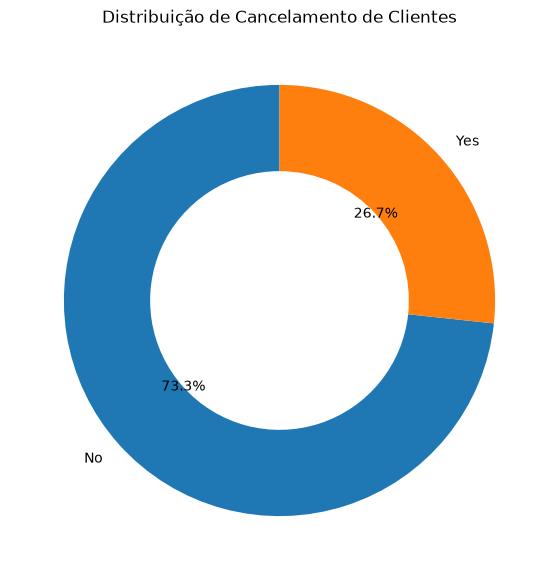

In [24]:
cancelamento = df_silver["Cancelamento"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    cancelamento,
    labels=cancelamento.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Distribuição de Cancelamento de Clientes")
plt.show()

### 2. Taxa de Cancelamento por Tipo de Contrato

O tipo de contrato costuma ser um dos fatores mais relacionados ao churn.
Este gráfico mostra a porcentagem de cancelamento em cada tipo de contrato.

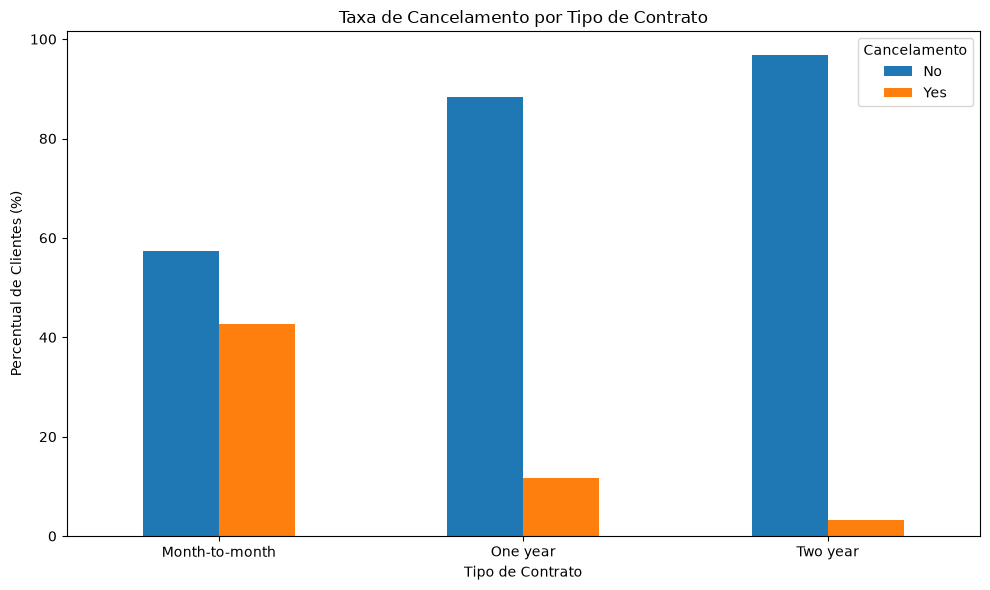

In [25]:
contrato_churn = pd.crosstab(
    df_silver["Contrato"],
    df_silver["Cancelamento"],
    normalize="index"
) * 100

contrato_churn.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Taxa de Cancelamento por Tipo de Contrato")
plt.xlabel("Tipo de Contrato")
plt.ylabel("Percentual de Clientes (%)")
plt.xticks(rotation=0)
plt.legend(title="Cancelamento")
plt.tight_layout()
plt.show()

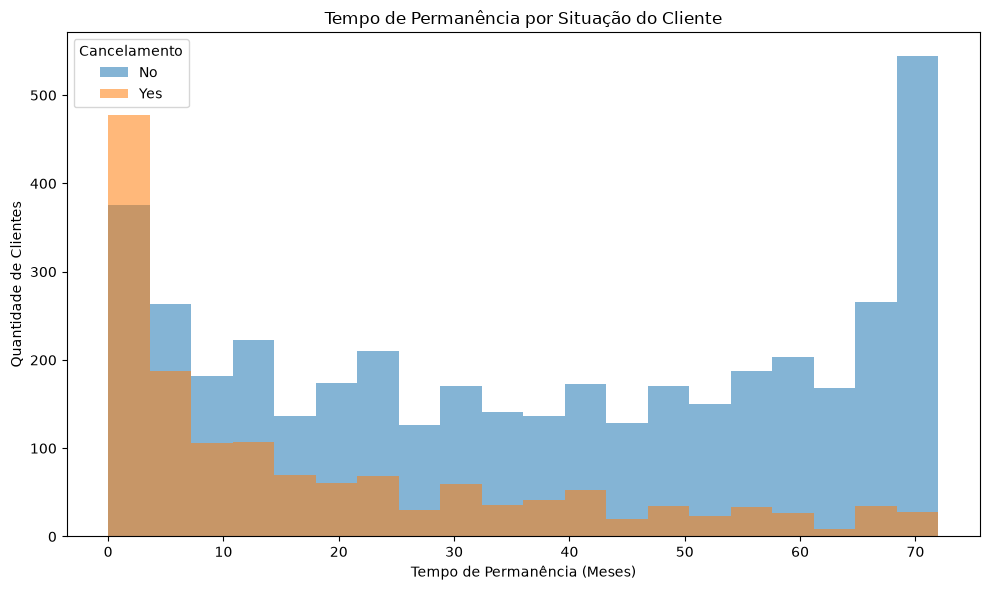

In [27]:
plt.figure(figsize=(10, 6))

for situacao in df_silver["Cancelamento"].dropna().unique():
    dados = df_silver.loc[
        df_silver["Cancelamento"] == situacao,
        "Tempo_Permanencia_Meses"   # ou Tempo_Permanencia_Meses se já renomeou
    ].dropna()
    
    plt.hist(dados, bins=20, alpha=0.55, label=str(situacao))

plt.title("Tempo de Permanência por Situação do Cliente")
plt.xlabel("Tempo de Permanência (Meses)")
plt.ylabel("Quantidade de Clientes")
plt.legend(title="Cancelamento")
plt.tight_layout()
plt.show()

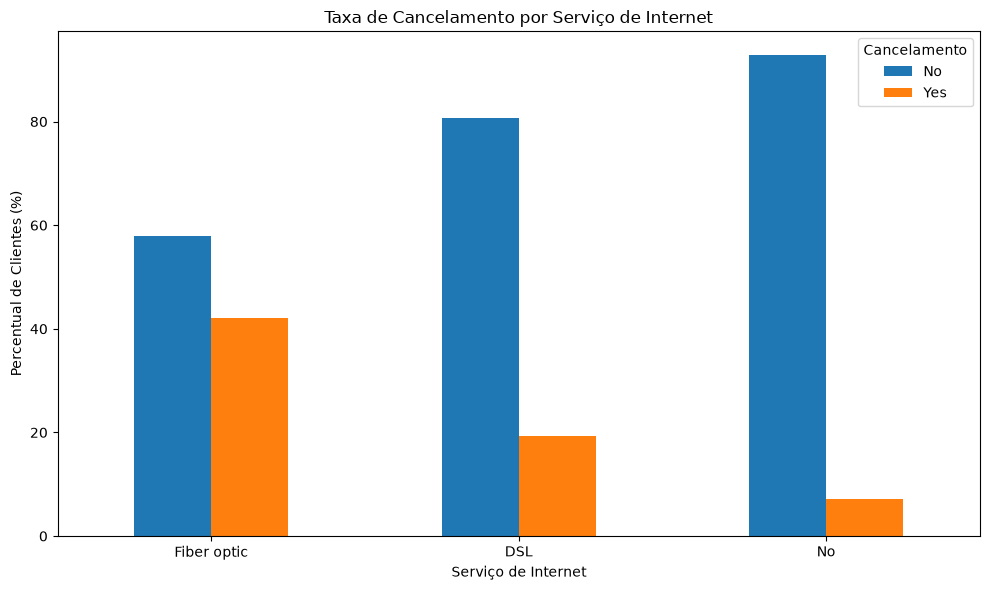

In [28]:
internet_churn = pd.crosstab(
    df_silver["Servico_Internet"],
    df_silver["Cancelamento"],
    normalize="index"
) * 100

internet_churn = internet_churn.sort_values(by="Yes", ascending=False)

internet_churn.plot(kind="bar", figsize=(10, 6))
plt.title("Taxa de Cancelamento por Serviço de Internet")
plt.xlabel("Serviço de Internet")
plt.ylabel("Percentual de Clientes (%)")
plt.xticks(rotation=0)
plt.legend(title="Cancelamento")
plt.tight_layout()
plt.show()

<Figure size 900x600 with 0 Axes>

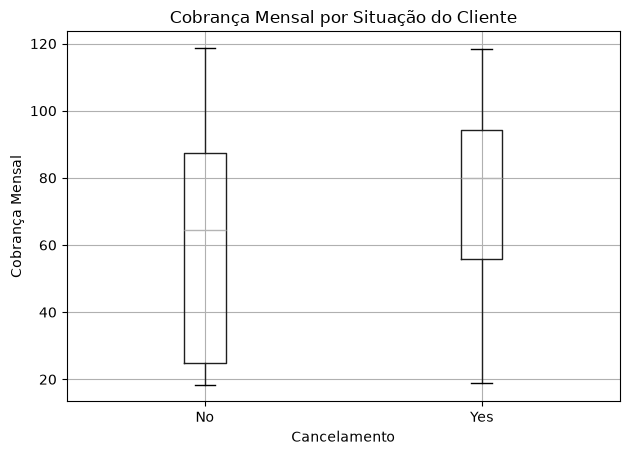

In [29]:
plt.figure(figsize=(9, 6))
df_silver.boxplot(column="Cobranca_Mensal", by="Cancelamento")
plt.title("Cobrança Mensal por Situação do Cliente")
plt.suptitle("")
plt.xlabel("Cancelamento")
plt.ylabel("Cobrança Mensal")
plt.tight_layout()
plt.show()

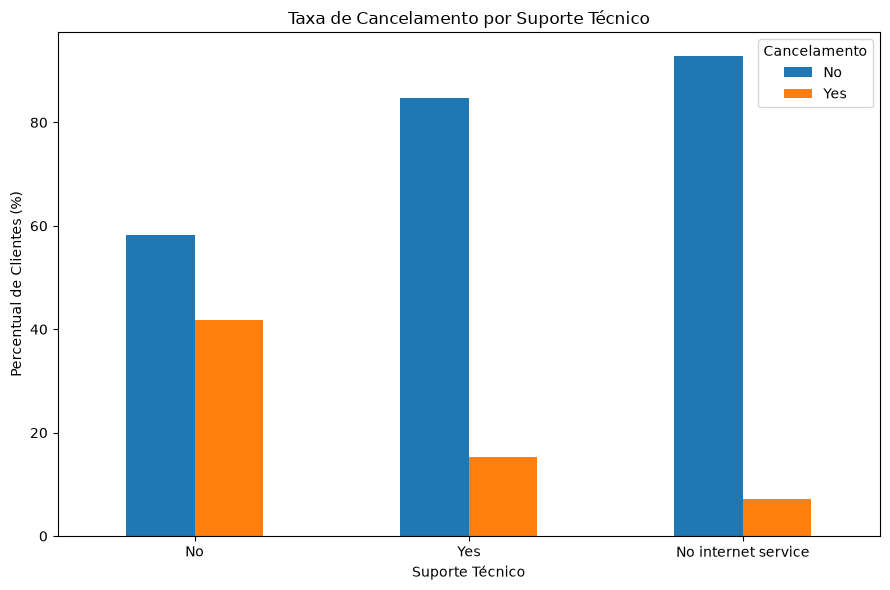

In [30]:
suporte_churn = pd.crosstab(
    df_silver["Suporte_Tecnico"],
    df_silver["Cancelamento"],
    normalize="index"
) * 100

suporte_churn = suporte_churn.sort_values(by="Yes", ascending=False)

suporte_churn.plot(kind="bar", figsize=(9, 6))
plt.title("Taxa de Cancelamento por Suporte Técnico")
plt.xlabel("Suporte Técnico")
plt.ylabel("Percentual de Clientes (%)")
plt.xticks(rotation=0)
plt.legend(title="Cancelamento")
plt.tight_layout()
plt.show()

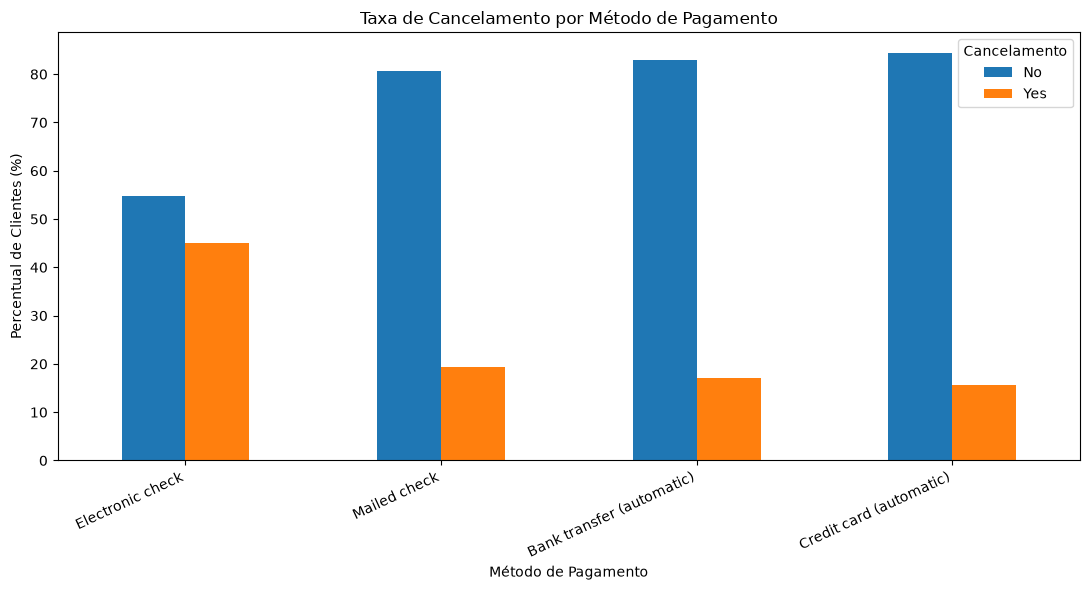

In [31]:
pagamento_churn = pd.crosstab(
    df_silver["Metodo_Pagamento"],
    df_silver["Cancelamento"],
    normalize="index"
) * 100

pagamento_churn = pagamento_churn.sort_values(by="Yes", ascending=False)

pagamento_churn.plot(kind="bar", figsize=(11, 6))
plt.title("Taxa de Cancelamento por Método de Pagamento")
plt.xlabel("Método de Pagamento")
plt.ylabel("Percentual de Clientes (%)")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Cancelamento")
plt.tight_layout()
plt.show()

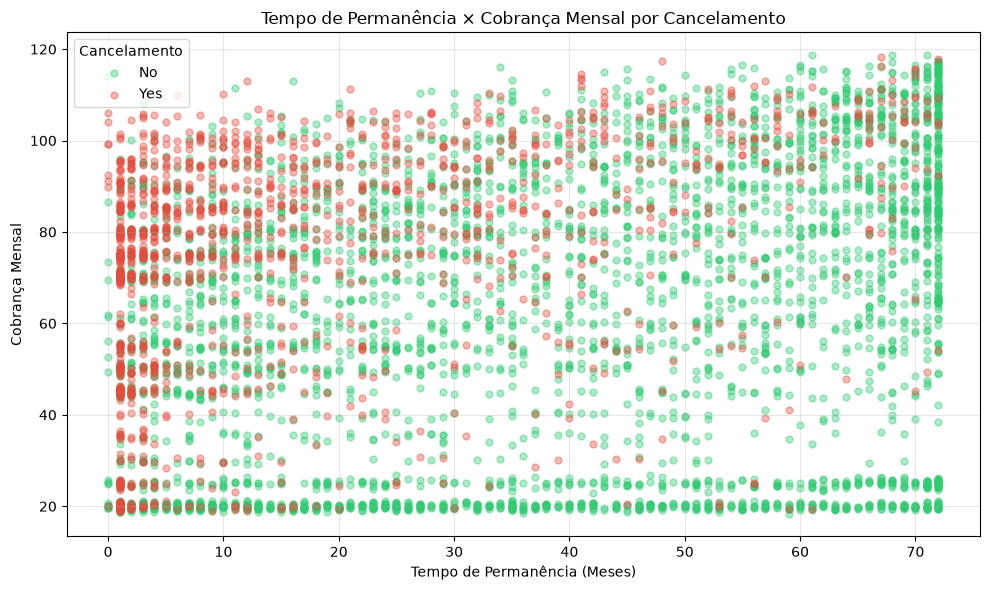

In [33]:
plt.figure(figsize=(10, 6))

# Separando por cancelamento para ficar mais claro
for situacao, cor in zip(["No", "Yes"], ["#2ecc71", "#e74c3c"]):
    dados = df_silver[df_silver["Cancelamento"] == situacao]
    plt.scatter(
        dados["Tempo_Permanencia_Meses"],
        dados["Cobranca_Mensal"],
        alpha=0.4,
        s=25,
        label=situacao,
        c=cor
    )

plt.title("Tempo de Permanência × Cobrança Mensal por Cancelamento")
plt.xlabel("Tempo de Permanência (Meses)")
plt.ylabel("Cobrança Mensal")
plt.legend(title="Cancelamento")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()